[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/omarcevi/pytorch-finance-workshop/blob/main/notebooks/workshop_solution.ipynb)

# Finansal Verilerle Yapay Zekâyı Buluşturmak (Çözüm Defteri)
**Işık IEEE Computer Society — PyTorch Atölyesi**  
📍 Işık Üniversitesi Şile Kampüsü, DMF-214 · 🗓️ 18 Kasım 2026 Çarşamba, 16:30–18:45  
🔗 **Adım Adım Rehber:** [omarcevi.dev/workshops/pytorch-finance-workshop](https://omarcevi.dev/workshops/pytorch-finance-workshop/)

> ⚠️ **Önemli Uyarı (Yatırım Tavsiyesi Değildir):** Bu atölyedeki tüm kodlar, modeller ve analizler yalnızca **makine öğrenmesi ve PyTorch eğitimi** amaçlıdır. Hiçbir içerik yatırım tavsiyesi niteliği taşımaz ve buradaki modeller gerçek alım-satım kararlarında **kullanılmamalıdır**.

### Ortam Hazırlığı
İlk hücremiz gerekli yardımcı modülü (`workshop_utils.py`) çalışma ortamına indirir ve sonuçların her bilgisayarda birebir aynı çıkması için rastgelelik tohumlarını (`seed`) sabitler.

In [1]:
# Çalışma ortamını hazırla ve rastgelelik tohumunu sabitle
import pathlib, sys, urllib.request
for _p in [pathlib.Path("src"), pathlib.Path("../src"), pathlib.Path("/content/pytorch-finance-workshop/src")]:
    if (_p / "workshop_utils.py").exists() and str(_p.resolve()) not in sys.path:
        sys.path.insert(0, str(_p.resolve()))
if not any((pathlib.Path(p) / "workshop_utils.py").exists() for p in sys.path + ["."]):
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/omarcevi/pytorch-finance-workshop/main/src/workshop_utils.py",
        "workshop_utils.py",
    )
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader

from workshop_utils import (
    DEFAULT_TICKERS,
    FEATURE_COLS,
    GRUModel,
    LSTMModel,
    PriceWindowDataset,
    SlidingWindowDataset,
    TinyTransformerModel,
    backtest_with_costs,
    build_features,
    chronological_split,
    compute_rsi,
    fit_scaler_on_train,
    load_prices,
    plot_chronological_split,
    plot_direction_results,
    plot_ohlcv,
    plot_price_deception,
    plot_training_curves,
    plot_zoom_and_lag,
    set_seed,
    train_direction_classifier,
    train_price_lstm,
    walk_forward_evaluation,
    yetistir_bolum_1,
    yetistir_bolum_2,
    yetistir_bolum_3,
    yetistir_bolum_4,
    yetistir_bolum_5,
    yetistir_bolum_6,
)

set_seed(42)
print(f"PyTorch sürümü: {torch.__version__} | Cihaz: CPU")

PyTorch sürümü: 2.14.1+cu130 | Cihaz: CPU


---
## Bölüm 0 · Giriş: Bu Grafikle Para Kazanabilir miyiz? (16:30–16:40)

İnternette *"LSTM ile Hisse Senedi Fiyat Tahmini"* araması yaptığınızda karşınıza hemen her zaman aşağıdaki gibi bir grafik çıkar: mavi çizgi gerçek fiyatı, kırmızı kesikli çizgi ise yapay zekâ modelinin tahminini gösterir. İki çizgi neredeyse üst üste binmiştir!

Peki **bu modelle gerçekten para kazanabilir miyiz?** Yoksa gözümüzün önünde çok ince bir yanılsama mı var? Cevabı Bölüm 4'e kadar saklıyoruz — önce bu modeli sıfırdan kendi ellerimizle kuralım.

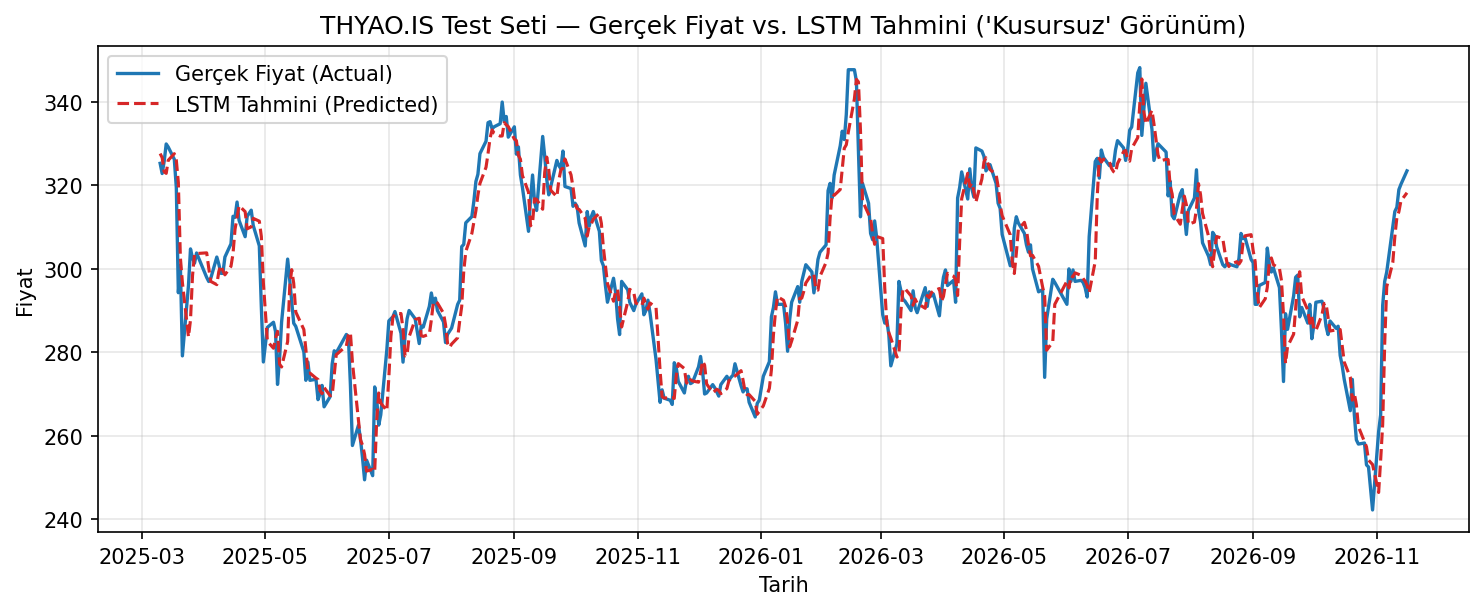

In [2]:
# Bölüm 4'te eğiteceğimiz LSTM fiyat tahmin modelinin test seti çıktısını önceden görelim
import pathlib
from IPython.display import Image, display
from workshop_utils import plot_price_deception, yetistir_bolum_4

_hook_candidates = [
    pathlib.Path("docs/hook_preview.png"),
    pathlib.Path("../docs/hook_preview.png"),
    pathlib.Path("/content/pytorch-finance-workshop/docs/hook_preview.png"),
]
_hook_img = next((p for p in _hook_candidates if p.exists()), None)
if _hook_img is not None:
    display(Image(filename=str(_hook_img), width=780))
else:
    _s4 = yetistir_bolum_4("THYAO.IS")
    plot_price_deception(_s4["test_dates"], _s4["price_res"]["actual_prices"], _s4["price_res"]["predicted_prices"])
    plt.show()

---
## Bölüm 1 · Kurulum ve Veri (16:40–16:55)

Finansal zaman serilerinde her işlem günü beş temel sayıyla özetlenir (**OHLCV**): **O**pen (Açılış), **H**igh (Gün içi en yüksek), **L**ow (Gün içi en düşük), **C**lose (Kapanış) ve **V**olume (İşlem hacmi). Hisseler zaman içinde temettü dağıtır veya bölünür; bu yüzden ham fiyatlar yerine temettü ve bölünmelere göre düzeltilmiş (**auto-adjusted**) fiyatları kullanırız ki geçmişte yapay fiyat düşüşleri görünmesin.

> 💡 **Geride mi kaldınız?** Her bölümün başındaki **"🔄 Yetiştir"** hücresini çalıştırarak o bölüme kadar gereken tüm değişkenleri tek tıkla oluşturabilirsiniz.

In [3]:
# @title 🔄 Yetiştir: Bölüm 1 (Çalışma zamanı sıfırlandıysa çalıştırın) { display-mode: "form" }
import pathlib, sys, urllib.request
for _p in [pathlib.Path("src"), pathlib.Path("../src"), pathlib.Path("/content/pytorch-finance-workshop/src")]:
    if (_p / "workshop_utils.py").exists() and str(_p.resolve()) not in sys.path:
        sys.path.insert(0, str(_p.resolve()))
if not any((pathlib.Path(p) / "workshop_utils.py").exists() for p in sys.path + ["."]):
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/omarcevi/pytorch-finance-workshop/main/src/workshop_utils.py",
        "workshop_utils.py",
    )
from workshop_utils import set_seed, load_prices, plot_ohlcv
set_seed(42)
TICKER = "THYAO.IS"
print("✅ Bölüm 1 ortamı hazır.")

✅ Bölüm 1 ortamı hazır.


`load_prices` fonksiyonu önce canlı olarak Yahoo Finance (`yfinance`) üzerinden veri indirmeyi dener; kampüs ağında hız sınırına (rate limit) takılırsa otomatik olarak yedek (snapshot) veriyi yükler. Şimdi Türk Hava Yolları (`THYAO.IS`) verisini indirelim ve ilk/son satırlarını inceleyelim.

In [4]:
TICKER = "THYAO.IS"

# BEGIN SOLUTION: load_prices fonksiyonu ile TICKER verisini raw_df değişkenine yükleyin
raw_df = load_prices(TICKER, start="2015-01-01", end="2026-11-17")
# END SOLUTION

print(f"Veri boyutu: {raw_df.shape} | Tarih aralığı: {raw_df.index.min().date()} -> {raw_df.index.max().date()}")
display(raw_df.tail(5))

ℹ️ THYAO.IS için yedek veri (snapshot) kullanılıyor.
Veri boyutu: (3023, 5) | Tarih aralığı: 2015-01-01 -> 2026-11-16


,Open,High,Low,Close,Volume
Date,,,,,
2026-11-10,311.50,318.25,311.00,313.75,49074691
2026-11-11,312.25,318.25,310.75,314.75,32338328
2026-11-12,315.50,325.75,315.50,319.00,48809018
2026-11-13,315.75,323.50,315.00,320.25,29607838
2026-11-16,319.75,324.50,318.50,323.50,27128552


Veriyi modele sokmadan önce her zaman görselleştirerek kontrol etmeliyiz. Kapanış fiyatını ve işlem hacmini alt alta çizdirelim.

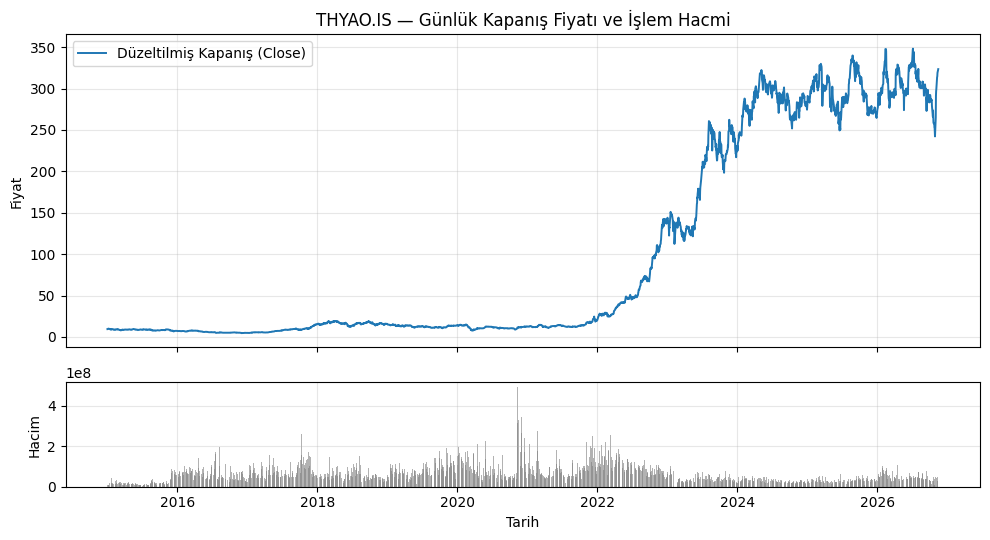

In [5]:
fig = plot_ohlcv(raw_df, ticker=TICKER)
plt.show()

---
## Bölüm 2 · Temizlik, Özellikler ve Veri Sızıntısı (16:55–17:15)

Borsa hafta sonları ve resmi tatillerde kapalıdır; ayrıca ham fiyat serileri zamanla yükseldiği için **durağan (stationary)** değildir (2015'teki 6 TL ile 2026'daki 300 TL aynı ölçekte değildir). Bu nedenle modelleri ham fiyatlar yerine **logaritmik getiri** ($r_t = \ln(P_t / P_{t-1})$), hareketli ortalama, volatilite ve RSI gibi ölçekten bağımsız özellikler üzerinde kurarız.

In [6]:
# @title 🔄 Yetiştir: Bölüm 2 (Önceki bölümü atladıysanız çalıştırın) { display-mode: "form" }
import pathlib, sys, urllib.request
for _p in [pathlib.Path("src"), pathlib.Path("../src"), pathlib.Path("/content/pytorch-finance-workshop/src")]:
    if (_p / "workshop_utils.py").exists() and str(_p.resolve()) not in sys.path:
        sys.path.insert(0, str(_p.resolve()))
if not any((pathlib.Path(p) / "workshop_utils.py").exists() for p in sys.path + ["."]):
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/omarcevi/pytorch-finance-workshop/main/src/workshop_utils.py",
        "workshop_utils.py",
    )
from workshop_utils import yetistir_bolum_1, compute_rsi, chronological_split, fit_scaler_on_train, plot_chronological_split, FEATURE_COLS
_s1 = yetistir_bolum_1("THYAO.IS")
TICKER = _s1["ticker"]
raw_df = _s1["raw_df"]

ℹ️ THYAO.IS için yedek veri (snapshot) kullanılıyor.
✅ Bölüm 1 hazır: THYAO.IS için 3023 günlük OHLCV verisi yüklendi.


Eksik günleri doldururken yalnızca geçmişteki son değeri ileri taşırız (`ffill`); gelecekteki değeri geçmişe taşımak (`bfill`) geleceği görmek demektir. Ardından günlük logaritmik getiriyi (`log_return`), 5 günlük ortalama getiriyi (`roll_mean_5`), 10 günlük volatiliteyi (`roll_std_10`) ve 14 günlük RSI göstergesini hesaplayalım.

In [7]:
feat_df = raw_df[["Open", "High", "Low", "Close", "Volume"]].ffill().dropna().copy()

# BEGIN SOLUTION: log_return, roll_mean_5 (5 günlük ortalama) ve roll_std_10 (10 günlük std) sütunlarını hesaplayın
feat_df["log_return"] = np.log(feat_df["Close"] / feat_df["Close"].shift(1))
feat_df["roll_mean_5"] = feat_df["log_return"].rolling(window=5).mean()
feat_df["roll_std_10"] = feat_df["log_return"].rolling(window=10).std()
# END SOLUTION

feat_df["rsi_14"] = compute_rsi(feat_df["Close"], period=14) / 100.0
feat_df["up_day"] = (feat_df["log_return"] > 0.0).astype(np.float32)
feat_df = feat_df.dropna().copy()
print("Özellik tablosu boyutu:", feat_df.shape)
display(feat_df[["Close", "log_return", "roll_mean_5", "roll_std_10", "rsi_14", "up_day"]].tail(4))

Özellik tablosu boyutu: (3009, 10)


,Close,log_return,roll_mean_5,roll_std_10,rsi_14,up_day
Date,,,,,,
2026-11-11,314.75,0.003182,0.015519,0.038801,0.759520,1.0
2026-11-12,319.00,0.013412,0.014292,0.038049,0.818810,1.0
2026-11-13,320.25,0.003911,0.013565,0.031575,0.829889,1.0
2026-11-16,323.50,0.010097,0.008525,0.027245,0.835131,1.0


### Kronolojik Bölme (Train / Validation / Test)
Zaman serilerinde `train_test_split(..., shuffle=True)` **asla kullanılmaz**; çünkü 2025 yılının verisiyle eğitilen bir modeli 2021 yılı üzerinde test etmek geleceği ezberlemektir. Veriyi zaman sırasıyla **%70 Eğitim (Train)**, **%15 Doğrulama (Val)** ve **%15 Test** olarak üçe bölüyoruz.

Train: 2106 gün (2015-01-21 -> 2023-04-05)
Val  : 451 gün (2023-04-06 -> 2025-01-24)
Test : 452 gün (2025-01-27 -> 2026-11-16)


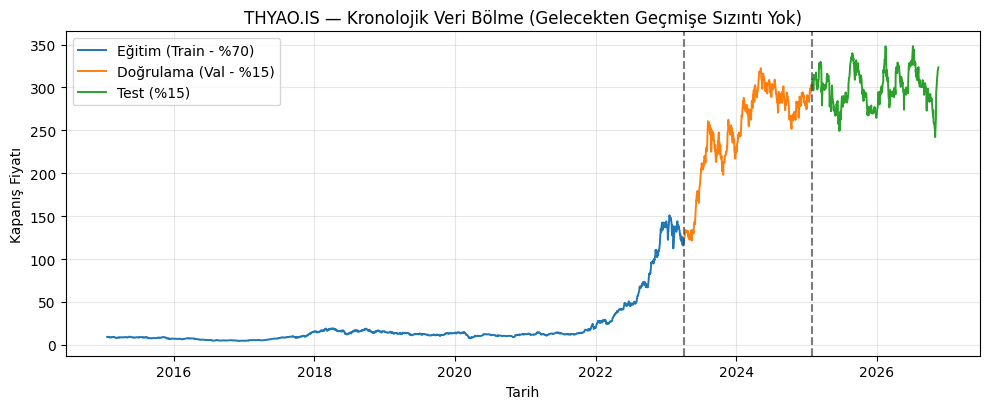

In [8]:
# BEGIN SOLUTION: chronological_split fonksiyonu ile feat_df tablosunu %70 train, %15 val, %15 test olarak bölün
train_df, val_df, test_df = chronological_split(feat_df, train_ratio=0.70, val_ratio=0.15)
# END SOLUTION

print(f"Train: {len(train_df)} gün ({train_df.index[0].date()} -> {train_df.index[-1].date()})")
print(f"Val  : {len(val_df)} gün ({val_df.index[0].date()} -> {val_df.index[-1].date()})")
print(f"Test : {len(test_df)} gün ({test_df.index[0].date()} -> {test_df.index[-1].date()})")
fig = plot_chronological_split(train_df, val_df, test_df, ticker=TICKER)
plt.show()

### Neden Scaler Yalnızca Eğitim (Train) Verisinde Fit Edilir?
Özellikleri ortalaması 0, standart sapması 1 olacak şekilde ölçeklerken (`StandardScaler`), `scaler.fit()` işlemini **yalnızca `train_df`** üzerinde çağırırız. Eğer `fit()` işlemini tüm veri üzerinde yaparsak, 2025–2026 yıllarındaki piyasa oynaklığı ve ortalama getiri bilgisi 2018'deki eğitim örneklerine sızar (**veri sızıntısı / data leakage**).

In [9]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# BEGIN SOLUTION: scaler'ı yalnızca train_df[FEATURE_COLS] üzerinde fit_transform edin; val ve test üzerinde transform çağırın
x_train = scaler.fit_transform(train_df[FEATURE_COLS].values.astype(np.float32))
x_val = scaler.transform(val_df[FEATURE_COLS].values.astype(np.float32))
x_test = scaler.transform(test_df[FEATURE_COLS].values.astype(np.float32))
# END SOLUTION

print(f"Eğitim ortalaması (yaklaşık 0): {x_train.mean(axis=0).round(4)}")
print(f"Test ortalaması               : {x_test.mean(axis=0).round(4)}")

Eğitim ortalaması (yaklaşık 0): [-0.  0. -0.  0.]
Test ortalaması               : [-0.0415 -0.0932 -0.3625 -0.1527]


---
## Bölüm 3 · PyTorch Temelleri: Tensor, Dataset ve LSTM (17:15–17:35)

PyTorch'un temel yapı taşı `torch.Tensor` nesnesidir (NumPy dizilerine benzer ancak otomatik türev ve GPU/CPU hızlandırma destekler). Bir LSTM modeli girdiyi **`(batch_size, seq_len, num_features)`** (örnek sayısı, pencere uzunluğu, özellik sayısı) boyutunda 3 boyutlu bir tensör olarak bekler.

In [10]:
# @title 🔄 Yetiştir: Bölüm 3 (Önceki bölümü atladıysanız çalıştırın) { display-mode: "form" }
import pathlib, sys, urllib.request
for _p in [pathlib.Path("src"), pathlib.Path("../src"), pathlib.Path("/content/pytorch-finance-workshop/src")]:
    if (_p / "workshop_utils.py").exists() and str(_p.resolve()) not in sys.path:
        sys.path.insert(0, str(_p.resolve()))
if not any((pathlib.Path(p) / "workshop_utils.py").exists() for p in sys.path + ["."]):
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/omarcevi/pytorch-finance-workshop/main/src/workshop_utils.py",
        "workshop_utils.py",
    )
from workshop_utils import yetistir_bolum_2, SlidingWindowDataset, LSTMModel, set_seed, plot_training_curves
_s2 = yetistir_bolum_2("THYAO.IS")
TICKER = _s2["ticker"]
raw_df, feat_df = _s2["raw_df"], _s2["feat_df"]
train_df, val_df, test_df = _s2["train_df"], _s2["val_df"], _s2["test_df"]
scaler, x_train, x_val, x_test = _s2["scaler"], _s2["x_train"], _s2["x_val"], _s2["x_test"]

ℹ️ THYAO.IS için yedek veri (snapshot) kullanılıyor.
✅ Bölüm 1 hazır: THYAO.IS için 3023 günlük OHLCV verisi yüklendi.
✅ Bölüm 2 hazır: train=2106, val=451, test=452 satır ve 4 özellik ölçeklendi.


Önce küçük bir NumPy dizisini PyTorch tensörüne dönüştürelim ve boyutlarını (`shape`, `dtype`) görelim.

In [11]:
sample_tensor = torch.tensor(x_train[:5], dtype=torch.float32)
print(f"Tensör boyutu (shape): {sample_tensor.shape} | Veri tipi (dtype): {sample_tensor.dtype}")

Tensör boyutu (shape): torch.Size([5, 4]) | Veri tipi (dtype): torch.float32


### Kayan Pencere (`SlidingWindowDataset`) ve `DataLoader`
Modelimize son **30 iş gününün** özelliklerini (`idx : idx + 30`) verip **31. günün** (`idx + 30`) değerini tahmin ettireceğiz.
> 📌 **Önemli Not:** Eğitim, doğrulama ve test ayrımımız tamamen kronolojiktir. Ancak eğitim kümesinin *kendi içindeki* 30 günlük pencereleri `DataLoader(..., shuffle=True)` ile karıştırmak güvenlidir; çünkü her pencere kendi 30 günlük iç zaman sırasını zaten korur ve gradyan inişinin (SGD/Adam) daha kararlı öğrenmesini sağlar.

In [12]:
WINDOW_SIZE = 30
BATCH_SIZE = 64

y_train_ret = train_df["log_return"].values.astype(np.float32)
y_val_ret = val_df["log_return"].values.astype(np.float32)

# BEGIN SOLUTION: SlidingWindowDataset ile train_ds ve val_ds oluşturup DataLoader'a sarın (train için shuffle=True)
train_ds = SlidingWindowDataset(x_train, y_train_ret, window_size=WINDOW_SIZE)
val_ds = SlidingWindowDataset(x_val, y_val_ret, window_size=WINDOW_SIZE)
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False)
# END SOLUTION

sample_bx, sample_by = next(iter(train_loader))
print(f"Giriş batch boyutu (batch, seq_len, features): {sample_bx.shape}")
print(f"Hedef batch boyutu (batch,)                  : {sample_by.shape}")

Giriş batch boyutu (batch, seq_len, features): torch.Size([64, 30, 4])
Hedef batch boyutu (batch,)                  : torch.Size([64])


### `nn.Module` ile LSTM Mimarisi ve Boyut Takibi
`nn.LSTM(input_dim, hidden_dim, batch_first=True)` katmanı her zaman adımı için bir gizli durum (`out` boyutu: `(batch, seq_len, hidden_dim)`) üretir. Biz yalnızca pencerenin **son gününe** ait özeti (`out[:, -1, :]`, boyutu: `(batch, hidden_dim)`) alıp doğrusal katmandan (`nn.Linear(hidden_dim, 1)`) geçiririz.

In [13]:
class SimpleLSTM(nn.Module):
    def __init__(self, input_dim: int, hidden_dim: int = 32) -> None:
        super().__init__()
        self.lstm = nn.LSTM(input_dim, hidden_dim, batch_first=True)
        self.fc = nn.Linear(hidden_dim, 1)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # BEGIN SOLUTION: x'i self.lstm'den geçirin, son zaman adımını (out[:, -1, :]) self.fc'ye verip squeeze(-1) döndürün
        out, _ = self.lstm(x)
        last_step = out[:, -1, :]
        return self.fc(last_step).squeeze(-1)
        # END SOLUTION

set_seed(42)
demo_model = SimpleLSTM(input_dim=len(FEATURE_COLS), hidden_dim=32)
with torch.no_grad():
    lstm_out, _ = demo_model.lstm(sample_bx)
    pred_out = demo_model(sample_bx)
print(f"1) Giriş tensörü (bx)          : {sample_bx.shape}")
print(f"2) LSTM tüm adımlar (lstm_out) : {lstm_out.shape}")
print(f"3) Son zaman adımı ([:, -1, :]): {lstm_out[:, -1, :].shape}")
print(f"4) Model çıktısı (pred_out)    : {pred_out.shape}")

1) Giriş tensörü (bx)          : torch.Size([64, 30, 4])
2) LSTM tüm adımlar (lstm_out) : torch.Size([64, 30, 32])
3) Son zaman adımı ([:, -1, :]): torch.Size([64, 32])
4) Model çıktısı (pred_out)    : torch.Size([64])


### PyTorch Eğitim Döngüsü (Training Loop)
PyTorch'ta her eğitim adımında 5 temel komut çalışır: `optimizer.zero_grad()` (eski türevleri sıfırla), `pred = model(bx)` (ileri besleme), `loss = criterion(pred, by)` (hatayı hesapla), `loss.backward()` (geriye yayılımla türevleri al) ve `optimizer.step()` (ağırlıkları güncelle).

Son Epoch (10) -> Train MSE: 0.000646 | Val MSE: 0.000509


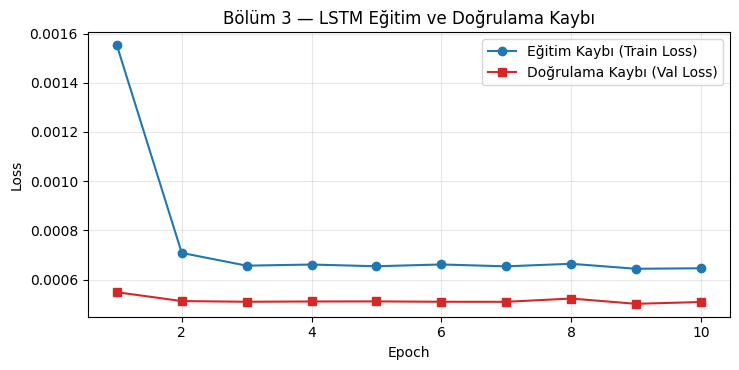

In [14]:
set_seed(42)
demo_model = SimpleLSTM(input_dim=len(FEATURE_COLS), hidden_dim=32)
optimizer = torch.optim.Adam(demo_model.parameters(), lr=0.001)
criterion = nn.MSELoss()

train_losses, val_losses = [], []
for epoch in range(10):
    demo_model.train()
    batch_losses = []
    for bx, by in train_loader:
        # BEGIN SOLUTION: 5 adımlı PyTorch eğitim döngüsünü yazın (zero_grad, forward, loss, backward, step)
        optimizer.zero_grad()
        pred = demo_model(bx)
        loss = criterion(pred, by)
        loss.backward()
        optimizer.step()
        # END SOLUTION
        batch_losses.append(loss.item())
    train_losses.append(float(np.mean(batch_losses)))

    demo_model.eval()
    with torch.no_grad():
        v_loss = np.mean([criterion(demo_model(vx), vy).item() for vx, vy in val_loader])
    val_losses.append(float(v_loss))

print(f"Son Epoch (10) -> Train MSE: {train_losses[-1]:.6f} | Val MSE: {val_losses[-1]:.6f}")
fig = plot_training_curves(train_losses, val_losses, title="Bölüm 3 — LSTM Eğitim ve Doğrulama Kaybı")
plt.show()

---
## ☕ Ara (17:35–17:45 · 10 Dakika Mola)

Çayınızı/kahvenizi alın! Moladan döndüğümüzde Bölüm 0'da gördüğümüz o **"kusursuz" fiyat tahmini grafiğini** üreteceğiz ve arkasındaki sürprizi ortaya çıkaracağız.

---
## Bölüm 4 · Fiyat Tahmini ve Sürpriz (17:45–18:05)

Şimdi internetteki pek çok eğitim yazısının yaptığı şeyi yapalım: LSTM modeline son 30 günün **kapanış fiyatlarını** verip **yarının kapanış fiyatını (TL)** tahmin ettirelim.

> 💡 **Teknik Not (İkinci Tuzak — Aktivasyon Doyması):** `THYAO.IS` fiyatı 2015'te 5 TL iken 2026'da 300 TL'nin üzerindedir. Tüm eğitim setine tek bir `StandardScaler` uygularsanız, test setindeki fiyatlar $z > 10$ değerine çıkar ve LSTM'in `tanh`/`sigmoid` kapıları doyuma (saturation) ulaşarak düz bir çizgiye kilitlenir. Bu tuzağa düşmemek için `PriceWindowDataset` her 30 günlük pencereyi kendi ilk gününe göre (`fiyat / ilk_gün - 1`) normalize eder ve tahmini tekrar TL'ye çevirir.

In [15]:
# @title 🔄 Yetiştir: Bölüm 4 (Moladan sonra temiz başlangıç için çalıştırın) { display-mode: "form" }
import pathlib, sys, urllib.request
for _p in [pathlib.Path("src"), pathlib.Path("../src"), pathlib.Path("/content/pytorch-finance-workshop/src")]:
    if (_p / "workshop_utils.py").exists() and str(_p.resolve()) not in sys.path:
        sys.path.insert(0, str(_p.resolve()))
if not any((pathlib.Path(p) / "workshop_utils.py").exists() for p in sys.path + ["."]):
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/omarcevi/pytorch-finance-workshop/main/src/workshop_utils.py",
        "workshop_utils.py",
    )
from workshop_utils import yetistir_bolum_3, train_price_lstm, plot_price_deception, plot_zoom_and_lag
_s3 = yetistir_bolum_3("THYAO.IS")
TICKER = _s3["ticker"]
train_df, val_df, test_df = _s3["train_df"], _s3["val_df"], _s3["test_df"]
WINDOW_SIZE = _s3["window_size"]

ℹ️ THYAO.IS için yedek veri (snapshot) kullanılıyor.
✅ Bölüm 1 hazır: THYAO.IS için 3023 günlük OHLCV verisi yüklendi.
✅ Bölüm 2 hazır: train=2106, val=451, test=452 satır ve 4 özellik ölçeklendi.
✅ Bölüm 3 hazır: Pencere boyutu=30, eğitim örnek sayısı=2076.


Fiyat tahmin modelimizi 15 epoch boyunca eğitelim ve test setindeki gerçek fiyatlarla LSTM tahminlerini aynı grafikte çizdirelim.

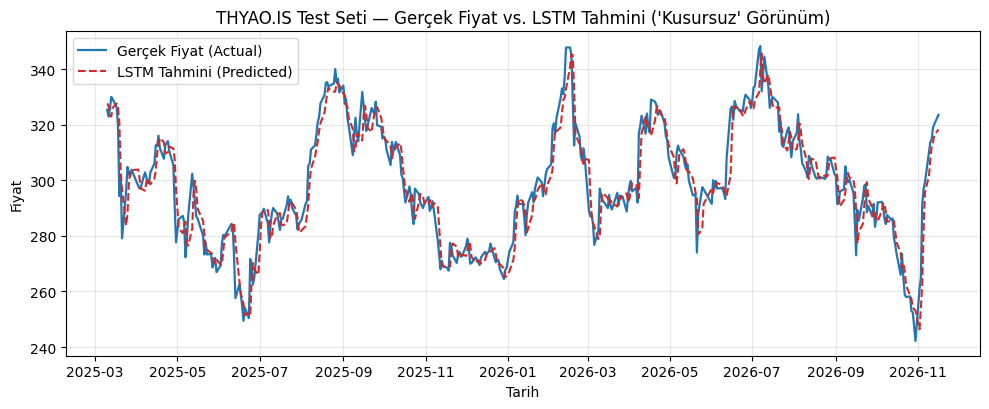

In [16]:
price_res = train_price_lstm(
    train_df["Close"].values,
    val_df["Close"].values,
    test_df["Close"].values,
    window_size=WINDOW_SIZE,
    epochs=15,
    seed=42,
)
test_dates = test_df.index[WINDOW_SIZE:]
actual_prices = price_res["actual_prices"]
predicted_prices = price_res["predicted_prices"]
naive_prices = price_res["naive_prices"]  # Her pencerenin son bilinen fiyatı (bugünün fiyatı P_t)

fig = plot_price_deception(test_dates, actual_prices, predicted_prices, ticker=TICKER)
plt.show()

### Sürpriz 1: Saf Referans Modeli (Naive Baseline — *"Yarın = Bugün"*)
Yukarıdaki grafik harika görünüyor, değil mi? Şimdi hiç yapay zekâ kullanmayan en basit referans modeli (**Naive Baseline**) kuralım: **"Yarının fiyatı, bugünün kapanış fiyatına eşittir ($\hat{P}_{t+1} = P_t$)."** İki modelin Ortalama Mutlak Hatasını (**MAE**, TL cinsinden) ve Kök Ortalama Kare Hatasını (**RMSE**) karşılaştıralım!

In [17]:
# BEGIN SOLUTION: actual_prices ile predicted_prices ve naive_prices arasındaki MAE ve RMSE değerlerini hesaplayın
lstm_mae = float(np.mean(np.abs(actual_prices - predicted_prices)))
naive_mae = float(np.mean(np.abs(actual_prices - naive_prices)))
lstm_rmse = float(np.sqrt(np.mean((actual_prices - predicted_prices) ** 2)))
naive_rmse = float(np.sqrt(np.mean((actual_prices - naive_prices) ** 2)))
# END SOLUTION

print(f"📊 LSTM Fiyat Modeli   -> MAE: {lstm_mae:.2f} TL | RMSE: {lstm_rmse:.2f} TL")
print(f"📏 Saf Referans (P_t)  -> MAE: {naive_mae:.2f} TL | RMSE: {naive_rmse:.2f} TL")
print(f"👉 Sonuç: Saf 'Yarın = Bugün' tahmini, LSTM'den {lstm_mae - naive_mae:.2f} TL daha düşük hataya sahip!")

📊 LSTM Fiyat Modeli   -> MAE: 5.07 TL | RMSE: 6.86 TL
📏 Saf Referans (P_t)  -> MAE: 4.55 TL | RMSE: 6.26 TL
👉 Sonuç: Saf 'Yarın = Bugün' tahmini, LSTM'den 0.52 TL daha düşük hataya sahip!


### Sürpriz 2: Grafiğe Yakınlaşınca Ortaya Çıkan 1 Günlük Gecikme (Lag)
Neden saf referans modeli LSTM'i geçiyor? Son 35 iş gününe büyüteçle bakalım ve LSTM tahmininin gerçek fiyat serisiyle olan korelasyonunu farklı gecikmelerle (`Lag 0` = aynı gün, `Lag 1` = dünün fiyatı) ölçelim.

Göreceksiniz ki **LSTM geleceği tahmin etmiyor; dünün fiyatını kopyalayıp 1 gün sağa kaydırıyor!** Çünkü fiyat serisi rastgele yürüyüşe ($P_{t+1} = P_t + \epsilon$) çok yakındır ve karesel hatayı (MSE) en aza indiren en kolay kestirme yol $\hat{P}_{t+1} \approx P_t$ tahminini üretmektir.

Tahminin BUGÜNÜN gerçek fiyatıyla korelasyonu (Lag 0): 0.9451
Tahminin DÜNÜN gerçek fiyatıyla korelasyonu   (Lag 1): 0.9915


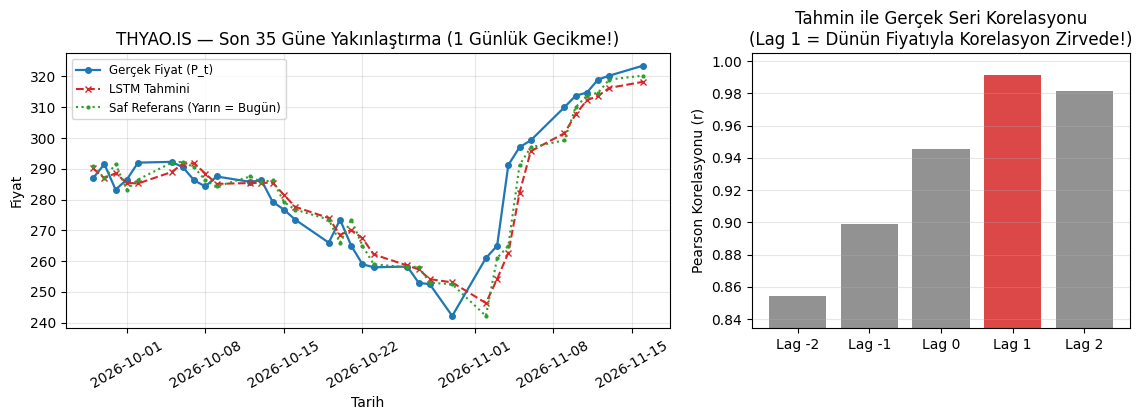

In [18]:
corr_today = float(np.corrcoef(predicted_prices[1:], actual_prices[1:])[0, 1])
corr_yesterday = float(np.corrcoef(predicted_prices[1:], actual_prices[:-1])[0, 1])
print(f"Tahminin BUGÜNÜN gerçek fiyatıyla korelasyonu (Lag 0): {corr_today:.4f}")
print(f"Tahminin DÜNÜN gerçek fiyatıyla korelasyonu   (Lag 1): {corr_yesterday:.4f}")

fig = plot_zoom_and_lag(test_dates, actual_prices, predicted_prices, naive_prices, ticker=TICKER, zoom_days=35)
plt.show()

---
## Bölüm 5 · Doğru Kurulum: Getiriler Üzerinden Yön Sınıflandırması (18:05–18:25)

Dünün fiyatını kopyalama tuzağından kurtulmak için problemi doğru tanımlamalıyız:
1. **Girdi:** Durağanlaştırılmış getiri ve teknik özellikler (`log_return`, `roll_mean_5`, `roll_std_10`, `rsi_14`).
2. **Hedef:** Yarının fiyat seviyesi değil, **yarının yönü** (`1` = Yükseliş $r_{t+1} > 0$, `0` = Düşüş $r_{t+1} \le 0$).
3. **Kayıp Fonksiyonu:** İkili sınıflandırma için `nn.BCEWithLogitsLoss()`.
4. **Referans Model:** Eğitim setindeki en sık görülen sınıfı seçen **Çoğunluk Sınıfı (Majority-Class) Referansı**.

In [19]:
# @title 🔄 Yetiştir: Bölüm 5 (Önceki bölümü atladıysanız çalıştırın) { display-mode: "form" }
import pathlib, sys, urllib.request
for _p in [pathlib.Path("src"), pathlib.Path("../src"), pathlib.Path("/content/pytorch-finance-workshop/src")]:
    if (_p / "workshop_utils.py").exists() and str(_p.resolve()) not in sys.path:
        sys.path.insert(0, str(_p.resolve()))
if not any((pathlib.Path(p) / "workshop_utils.py").exists() for p in sys.path + ["."]):
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/omarcevi/pytorch-finance-workshop/main/src/workshop_utils.py",
        "workshop_utils.py",
    )
from workshop_utils import yetistir_bolum_4, train_direction_classifier, walk_forward_evaluation, plot_direction_results, FEATURE_COLS
_s4 = yetistir_bolum_4("THYAO.IS")
TICKER = _s4["ticker"]
feat_df = _s4["feat_df"]
train_df, val_df, test_df = _s4["train_df"], _s4["val_df"], _s4["test_df"]
x_train, x_val, x_test = _s4["x_train"], _s4["x_val"], _s4["x_test"]
WINDOW_SIZE = _s4["window_size"]

ℹ️ THYAO.IS için yedek veri (snapshot) kullanılıyor.
✅ Bölüm 1 hazır: THYAO.IS için 3023 günlük OHLCV verisi yüklendi.
✅ Bölüm 2 hazır: train=2106, val=451, test=452 satır ve 4 özellik ölçeklendi.


✅ Bölüm 4 hazır: LSTM MAE=5.07 TL | Saf Referans (Yarın=Bugün) MAE=4.55 TL.


Şimdi `up_day` hedefiyle yön sınıflandırma modelimizi eğitelim ve Test Doğruluğu (`Accuracy`), Dengeli Doğruluk (`Balanced Accuracy`) ile Çoğunluk Sınıfı Referansını (`Majority Baseline`) karşılaştıralım.

In [20]:
y_train_dir = train_df["up_day"].values.astype(np.float32)
y_val_dir = val_df["up_day"].values.astype(np.float32)
y_test_dir = test_df["up_day"].values.astype(np.float32)

# BEGIN SOLUTION: train_direction_classifier fonksiyonunu çağırarak cls_res sözlüğünü elde edin
cls_res = train_direction_classifier(
    x_train,
    y_train_dir,
    x_val,
    y_val_dir,
    x_test,
    y_test_dir,
    window_size=WINDOW_SIZE,
    epochs=15,
    seed=42,
)
# END SOLUTION

print(f"🎯 LSTM Test Doğruluğu (Accuracy)         : %{cls_res['test_acc'] * 100:.2f}")
print(f"⚖️ LSTM Dengeli Doğruluk (Balanced Acc)   : %{cls_res['test_bal_acc'] * 100:.2f}")
print(f"📏 Çoğunluk Sınıfı Referansı (Baseline)   : %{cls_res['majority_acc'] * 100:.2f}")

🎯 LSTM Test Doğruluğu (Accuracy)         : %54.74
⚖️ LSTM Dengeli Doğruluk (Balanced Acc)   : %53.51
📏 Çoğunluk Sınıfı Referansı (Baseline)   : %51.90


### Walk-Forward (İleri Yürüyen) Doğrulama ve Neden Sonuç ~%50 Civarında?
Tek bir test bölgesi şansa bağlı olarak biraz yüksek veya düşük çıkabilir. Gerçekçi değerlendirme için **Walk-Forward Validation** kullanırız: modeli 4 ardışık zaman diliminde yeniden eğitip bir sonraki dönem üzerinde test ederiz (`scaler` her adımda yalnızca o adımın geçmiş verisiyle fit edilir).

> 🧠 **Neden dürüst doğruluk %50–%55 bandındadır?**
> 1. **Etkin Piyasa Hipotezi:** Herkesin erişebildiği geçmiş günlük fiyat bilgisi zaten fiyatların içine yansımıştır.
> 2. **Düşük Sinyal / Gürültü Oranı:** Günlük fiyat hareketlerinin büyük kısmı haber akışı ve rastgele likidite şoklarından (gürültüden) oluşur.
> 3. **Durağan Olmama (Rejim Değişimleri):** Faiz, enflasyon ve piyasa dinamikleri yıldan yıla değişir.
> *(İpucu: Eğer günlük finans verisinde %80+ yön doğruluğu görüyorsanız, neredeyse kesinlikle veri sızıntısı yapmışsınızdır!)*

,fold,train_end_date,test_end_date,accuracy,balanced_accuracy,majority_acc
0,1,2020-11-10,2022-05-11,0.505780,0.528184,0.459538
1,2,2022-05-11,2023-11-10,0.494220,0.489759,0.479769
2,3,2023-11-10,2025-05-15,0.543353,0.520701,0.528902
3,4,2025-05-15,2026-11-13,0.523121,0.515044,0.511561


Walk-Forward Ortalama Doğruluk: %51.66


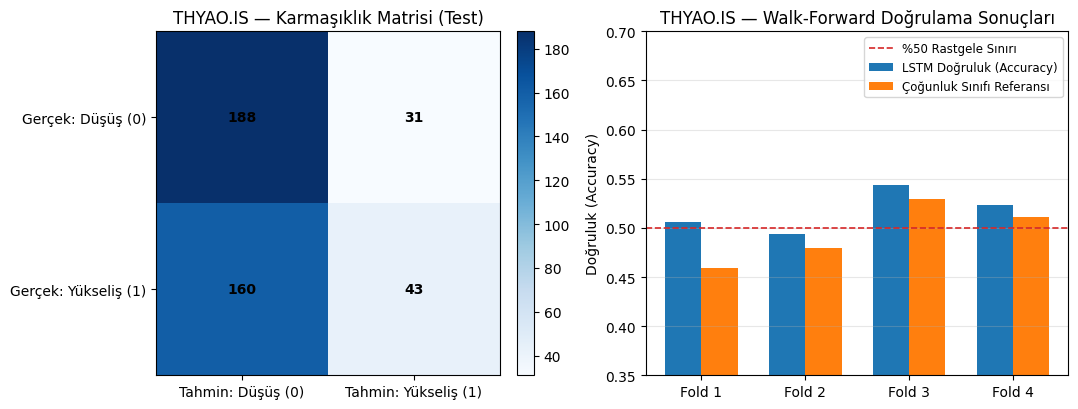

In [21]:
wf_res = walk_forward_evaluation(feat_df, FEATURE_COLS, n_splits=4, window_size=WINDOW_SIZE, epochs=10, seed=42)
wf_df = pd.DataFrame(wf_res)
display(wf_df)
print(f"Walk-Forward Ortalama Doğruluk: %{wf_df['accuracy'].mean() * 100:.2f}")

fig = plot_direction_results(cls_res["confusion_matrix"], wf_res, ticker=TICKER)
plt.show()

---
## Bölüm 6 · Meydan Okumalar (18:25–18:40)

Şimdi sıra sizde! Aşağıdaki meydan okumaları kendi hızınızda deneyin. Her birinin altında bir ipucu ve katlanmış (**Çözümü Göster**) hücresi yer alıyor.

In [22]:
# @title 🔄 Yetiştir: Bölüm 6 (Meydan okumalar için tüm değişkenleri hazırlar) { display-mode: "form" }
import pathlib, sys, urllib.request
for _p in [pathlib.Path("src"), pathlib.Path("../src"), pathlib.Path("/content/pytorch-finance-workshop/src")]:
    if (_p / "workshop_utils.py").exists() and str(_p.resolve()) not in sys.path:
        sys.path.insert(0, str(_p.resolve()))
if not any((pathlib.Path(p) / "workshop_utils.py").exists() for p in sys.path + ["."]):
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/omarcevi/pytorch-finance-workshop/main/src/workshop_utils.py",
        "workshop_utils.py",
    )
from workshop_utils import (
    yetistir_bolum_6, load_prices, build_features, chronological_split,
    fit_scaler_on_train, train_direction_classifier, backtest_with_costs,
    GRUModel, TinyTransformerModel, FEATURE_COLS,
)
_s6 = yetistir_bolum_6("THYAO.IS")
TICKER = _s6["ticker"]
feat_df = _s6["feat_df"]
train_df, val_df, test_df = _s6["train_df"], _s6["val_df"], _s6["test_df"]
x_train, x_val, x_test = _s6["x_train"], _s6["x_val"], _s6["x_test"]
cls_res = _s6["cls_res"]
WINDOW_SIZE = _s6["window_size"]

ℹ️ THYAO.IS için yedek veri (snapshot) kullanılıyor.
✅ Bölüm 1 hazır: THYAO.IS için 3023 günlük OHLCV verisi yüklendi.
✅ Bölüm 2 hazır: train=2106, val=451, test=452 satır ve 4 özellik ölçeklendi.


✅ Bölüm 5 hazır: Test Doğruluk (Accuracy)=0.547 | Dengeli Doğruluk=0.535 | Çoğunluk Sınıfı=0.519.
✅ Bölüm 6 (Meydan Okumalar) için tüm değişkenler hazır!


### Meydan Okuma 1: Kendi Sembolünü Dene (`ASELS.IS`, `BTC-USD`, `AAPL`) ve Hata Yönetimi
`load_prices` fonksiyonunu farklı bir sembolle (örneğin `"ASELS.IS"` veya `"BTC-USD"`) çalıştırın. Ayrıca var olmayan bir sembol (örneğin `"GECERSIZ_SEMBOL_XYZ"`) verdiğinizde Türkçe hata mesajının nasıl çalıştığını doğrulayın.
- **İpucu:** `try ... except ValueError as e:` bloğu kullanarak geçersiz sembol hatasını yakalayabilirsiniz.

In [23]:
# @title 💡 Çözüm 1: Farklı Sembol ve Geçersiz Sembol Kontrolü { display-mode: "form" }
asels_df = load_prices("ASELS.IS")
print(f"ASELS.IS yüklendi -> {len(asels_df)} gün, son kapanış: {asels_df['Close'].iloc[-1]:.2f} TL")

try:
    load_prices("GECERSIZ_SEMBOL_XYZ", force_fallback=True)
except ValueError as err:
    print(f"Beklenen Türkçe hata yakalandı: {err}")

ℹ️ ASELS.IS için yedek veri (snapshot) kullanılıyor.
ASELS.IS yüklendi -> 3023 gün, son kapanış: 353.00 TL
ℹ️ GECERSIZ_SEMBOL_XYZ için yedek veri (snapshot) kullanılıyor.


Beklenen Türkçe hata yakalandı: 'GECERSIZ_SEMBOL_XYZ' sembolü için ne Yahoo Finance'ten ne de yedek (snapshot) veriden veri alınabildi. Lütfen geçerli bir sembol girin (örn. 'THYAO.IS', 'ASELS.IS', 'AAPL').


### Meydan Okuma 2: Hacim Değişimi (`volume_change`) Özelliğini Modele Ekle
`build_features` fonksiyonu `volume_change` (logaritmik işlem hacmi değişimi) sütununu da üretir. Özellik listesine `"volume_change"` ekleyerek 5 özellikle yön sınıflandırma modelini yeniden eğitin.
- **İpucu:** `fit_scaler_on_train(train_df, val_df, test_df, cols_5)` çağrısıyla yeni ölçeklenmiş matrisleri oluşturun.

In [24]:
# @title 💡 Çözüm 2: 5 Özellik (Hacim Dahil) ile Sınıflandırma { display-mode: "form" }
feat_df_v = build_features(load_prices("THYAO.IS"))
tr_v, va_v, te_v = chronological_split(feat_df_v)
cols_5 = FEATURE_COLS + ["volume_change"]
_, x_tr5, x_va5, x_te5 = fit_scaler_on_train(tr_v, va_v, te_v, cols_5)

res_5 = train_direction_classifier(
    x_tr5, tr_v["up_day"].values,
    x_va5, va_v["up_day"].values,
    x_te5, te_v["up_day"].values,
    window_size=30, epochs=15, seed=42,
)
print(f"5 Özellikli Model -> Test Acc: %{res_5['test_acc']*100:.2f} | Balanced Acc: %{res_5['test_bal_acc']*100:.2f}")

ℹ️ THYAO.IS için yedek veri (snapshot) kullanılıyor.


5 Özellikli Model -> Test Acc: %55.69 | Balanced Acc: %54.62


### Meydan Okuma 3: `nn.LSTM` Yerine `nn.GRU` ve Farklı Pencere Boyutu Dene
`GRUModel` sınıfını ve `window_size=15` parametresini kullanarak modeli eğitin; LSTM ile hız ve doğruluk açısından karşılaştırın.
- **İpucu:** `train_direction_classifier(..., window_size=15, model_cls=GRUModel)` parametresini kullanabilirsiniz.

In [25]:
# @title 💡 Çözüm 3: GRU Modeli ve 15 Günlük Pencere { display-mode: "form" }
res_gru = train_direction_classifier(
    x_train, train_df["up_day"].values,
    x_val, val_df["up_day"].values,
    x_test, test_df["up_day"].values,
    window_size=15, epochs=15, seed=42, model_cls=GRUModel,
)
print(f"GRU (window=15) -> Test Acc: %{res_gru['test_acc']*100:.2f} | Balanced Acc: %{res_gru['test_bal_acc']*100:.2f}")

GRU (window=15) -> Test Acc: %52.63 | Balanced Acc: %51.53


### Meydan Okuma 4 (Bonus): Küçük Transformer Encoder ve İşlem Maliyetli Backtest
1. `TinyTransformerModel` ile yön tahminini deneyin.
2. `backtest_with_costs` fonksiyonunu kullanarak modelin tahmin sinyalleriyle **işlem maliyetsiz (brüt)** ve **işlem maliyetli (15 baz puan = %0.15 komisyon+makas)** getiriyi **Al-ve-Tut (Buy & Hold)** stratejisiyle karşılaştırın. Küçük bir doğruluk avantajının komisyonlarla nasıl eridiğini gözlemleyin!

TinyTransformer -> Test Acc: %54.74
İşlem sayısı: 29 | Al-ve-Tut Çarpanı: 0.99x | Brüt Strateji: 1.24x | Net (Maliyetli) Strateji: 1.18x


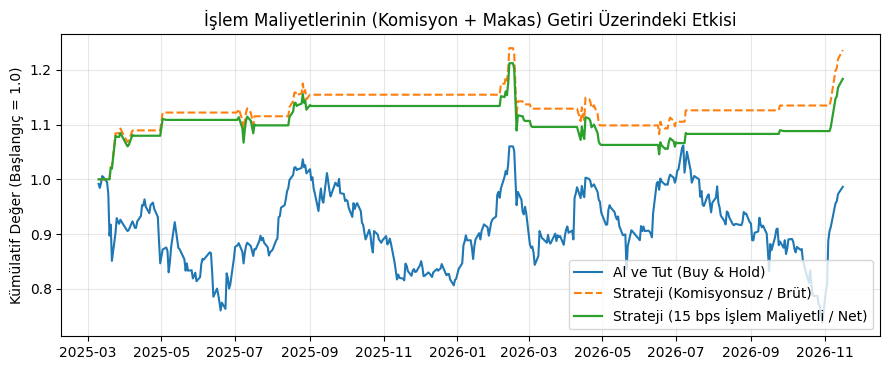

In [26]:
# @title 💡 Çözüm 4 (Bonus): TinyTransformer ve İşlem Maliyetli Backtest { display-mode: "form" }
res_tf = train_direction_classifier(
    x_train, train_df["up_day"].values,
    x_val, val_df["up_day"].values,
    x_test, test_df["up_day"].values,
    window_size=WINDOW_SIZE, epochs=12, seed=42, model_cls=TinyTransformerModel,
)
print(f"TinyTransformer -> Test Acc: %{res_tf['test_acc']*100:.2f}")

test_rets = test_df["log_return"].values[WINDOW_SIZE:]
bt = backtest_with_costs(test_rets, cls_res["y_pred"], cost_bps=15.0)
print(f"İşlem sayısı: {bt['n_trades']} | Al-ve-Tut Çarpanı: {bt['final_buy_hold']:.2f}x | "
      f"Brüt Strateji: {bt['final_gross']:.2f}x | Net (Maliyetli) Strateji: {bt['final_net']:.2f}x")

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(test_df.index[WINDOW_SIZE:], bt["cum_buy_hold"], label="Al ve Tut (Buy & Hold)", linewidth=1.5)
ax.plot(test_df.index[WINDOW_SIZE:], bt["cum_gross"], label="Strateji (Komisyonsuz / Brüt)", linestyle="--")
ax.plot(test_df.index[WINDOW_SIZE:], bt["cum_net"], label="Strateji (15 bps İşlem Maliyetli / Net)", linewidth=1.6)
ax.set_title("İşlem Maliyetlerinin (Komisyon + Makas) Getiri Üzerindeki Etkisi")
ax.set_ylabel("Kümülatif Değer (Başlangıç = 1.0)")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

---
## Bölüm 7 · Kapanış ve Özeti (18:40–18:45)

### Eve Götürülecek 3 Temel Ders
1. **Her Zaman Saf Bir Referansla (Naive Baseline) Karşılaştırın:** "Yarın = Bugün" tahminini geçemeyen bir derin öğrenme modeli, ne kadar karmaşık olursa olsun yalnızca dün gördüğü fiyatı tekrar ediyordur.
2. **Zaman Serilerini Yalnızca Zamana Göre Bölün:** Rastgele karıştırma (`shuffle`) geleceği geçmişe sızdırır; gerçekçi değerlendirme için kronolojik bölme ve **Walk-Forward** doğrulama şarttır.
3. **Veri Sızıntısı (Data Leakage) Her Yerde Saklanır:** `StandardScaler`'ı tüm veriye fit etmekten, eksik günleri geriye doğru doldurmaya (`bfill`) kadar en küçük hata bile yapay olarak yüksek ama gerçekte değersiz sonuçlar üretir.

### Gerçek Kantitatif (Quant) Ekipler Neyi Farklı Yapar?
- **Çoklu Veri Kaynakları:** Yalnızca günlük OHLCV değil; emir defteri (order book) mikro-yapısı, bilanço temelleri, makroekonomik seriler ve haber/duygu akışlarını birleştirirler.
- **Portföy ve Risk Yönetimi:** Tek bir hissenin yönünü bilmeye çalışmak yerine yüzlerce varlık arasında göreceli sıralama (cross-sectional ranking) ve volatilite/düşüş (drawdown) kontrolü yaparlar.
- **İşlem Maliyeti ve İcra (Execution):** Komisyon, alım-satım makası (bid-ask spread) ve piyasa etkisini (slippage) doğrudan kayıp fonksiyonuna dahil ederler.

### Faydalı Bağlantılar
- 📘 **Atölye Rehberi:** [omarcevi.dev/workshops/pytorch-finance-workshop](https://omarcevi.dev/workshops/pytorch-finance-workshop/)
- 🔥 **PyTorch Resmi Eğitimleri:** [pytorch.org/tutorials](https://pytorch.org/tutorials/)
- 📏 **Scikit-Learn TimeSeriesSplit:** [scikit-learn.org/stable/modules/cross_validation.html#time-series-split](https://scikit-learn.org/stable/modules/cross_validation.html#time-series-split)

> ⚠️ **Yasal Uyarı (Yatırım Tavsiyesi Değildir):** Bu çalışma ve içerdiği modeller yalnızca akademik ve pedagojik amaçlarla hazırlanmıştır; hiçbir koşulda finansal danışmanlık veya yatırım tavsiyesi olarak değerlendirilemez.